# 🕵️‍♀️​ Exploration of: Cognitive Distortion detetction dataset

link of the website: 
https://www.kaggle.com/datasets/sagarikashreevastava/cognitive-distortion-detetction-dataset?select=Annotated_data.csv


## Imports

In [1]:
import pandas as pd
import numpy as np

import string

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

In [2]:
data = pd.read_csv("/Users/abiboubou/code/youhsuanchang/project/archive-2/Annotated_data.csv")
data.head()
data.shape

(2530, 5)

In [3]:
data["Patient Question"]

0       Hello, I have a beautiful,smart,outgoing and a...
1       Since I was about 16 years old I’ve had these ...
2        So I’ve been dating on and off this guy for a...
3       My parents got divorced in 2004. My mother has...
4       I don’t really know how to explain the situati...
                              ...                        
2525    I’m a 21 year old female. I spent most of my l...
2526    I am 21 female and have not had any friends fo...
2527    From the U.S.: My brother is 19 years old and ...
2528    From the U.S.: I am a 21 year old woman who ha...
2529    I recently moved out on my ex-roommate because...
Name: Patient Question, Length: 2530, dtype: object

In [4]:
thrapist_response_data = pd.read_csv("/Users/abiboubou/code/youhsuanchang/project/archive-2/Therapist_responses.csv")
thrapist_response_data.head()

,Answer,Question,Id_Number
0,Thank you for writing. You did nothing wrong! ...,From a teen in Australia: This story is incred...,0
1,"At 63, you are still working on this. For that...",From a woman in the U.S.: My Therapist of eigh...,1
2,It’s impossible to give a diagnosis over the i...,I don’t even really know where to start. For t...,2
3,Congratulations on bringing your new baby into...,"From a woman in the UK: Hi, I have a 4 month o...",3
4,Thank you for explaining this situation. How u...,Me and my sister in law are both pregnant righ...,4


In [ ]:
X = data[["Patient Question"]]
X.head()

,Patient Question
0,"Hello, I have a beautiful,smart,outgoing and a..."
1,Since I was about 16 years old I’ve had these ...
2,So I’ve been dating on and off this guy for a...
3,My parents got divorced in 2004. My mother has...
4,I don’t really know how to explain the situati...


# ​📊​ Features (Patience Questions)

### Length 
num_of_unique_questions = 2529,
max length of the phrases = 29,
min length of the phrases = 1059,
mean length of the phrases = 167.3

In [6]:
X.shape

(2530, 1)

In [7]:
X.duplicated().value_counts()

False    2529
True        1
Name: count, dtype: int64

In [8]:
data.duplicated().value_counts()#->there is one question is the same but other informtion are not the same

False    2530
Name: count, dtype: int64

In [9]:
X[X.duplicated(keep=False)]

,Patient Question
464,I grew up in a upper middle class family. I wa...
506,I grew up in a upper middle class family. I wa...


In [10]:
X = X.drop_duplicates()
X.head()

,Patient Question
0,"Hello, I have a beautiful,smart,outgoing and a..."
1,Since I was about 16 years old I’ve had these ...
2,So I’ve been dating on and off this guy for a...
3,My parents got divorced in 2004. My mother has...
4,I don’t really know how to explain the situati...


In [11]:
num_of_unique_questions = X.shape[0]
num_of_unique_questions

2529

## Data Cleaning

In [12]:
def cleaning(sentence):

    # Basic cleaning
    sentence = sentence.strip() ## remove whitespaces
    sentence = sentence.lower() ## lowercase
    sentence = ''.join(char for char in sentence if not char.isdigit()) ## remove numbers

    # Advanced cleaning
    for punctuation in string.punctuation:
        sentence = sentence.replace(punctuation, '') ## remove punctuation

    tokenized_sentence = word_tokenize(sentence) ## tokenize
    stop_words = set(stopwords.words('english')) ## define stopwords

    tokenized_sentence_cleaned = [ ## remove stopwords
        w for w in tokenized_sentence if not w in stop_words
    ]

    lemmatized = [
        WordNetLemmatizer().lemmatize(word, pos = "v")
        for word in tokenized_sentence_cleaned
    ]

    cleaned_sentence = ' '.join(word for word in lemmatized)

    return cleaned_sentence


In [13]:
cleaned_documents = X["Patient Question"].apply(cleaning)
cleaned_documents

0       hello beautifulsmartoutgoing amaze five year o...
1       since years old ’ “ spell ” ’ impossible contr...
2       ’ date guy almost years years younger relation...
3       parent get divorce mother never recover severe...
4       ’ really know explain situation deal lot famil...
                              ...                        
2525    ’ year old female spend life isolate violent f...
2526    female friends years high achieve score really...
2527    us brother years old currently live parent col...
2528    us year old woman seriously involve older man ...
2529    recently move exroommate history psyche proble...
Name: Patient Question, Length: 2529, dtype: object

In [14]:
vectorizer = TfidfVectorizer()

vectorized_documents = vectorizer.fit_transform(cleaned_documents)
vectorized_documents = pd.DataFrame(
    vectorized_documents.toarray(),
    columns = vectorizer.get_feature_names_out()
)

vectorized_documents

,aa,ab,aback,abandon,abandonment,abcdxyz,abdomen,abdominal,abdominoplasty,abhor,...,zing,zip,zits,zoloft,zombie,zombies,zone,zyclidine,zyprexa,zyrtec
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2524,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2525,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2526,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2527,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
data['text_word_count'] = data["Patient Question"].fillna('').str.split().str.len()
data.head()

,Id_Number,Patient Question,Distorted part,Dominant Distortion,Secondary Distortion (Optional),text_word_count
0,4500,"Hello, I have a beautiful,smart,outgoing and a...",The voice are always fimilar (someone she know...,Personalization,NaN,131
1,4501,Since I was about 16 years old I’ve had these ...,I feel trapped inside my disgusting self and l...,Labeling,Emotional Reasoning,292
2,4502,So I’ve been dating on and off this guy for a...,NaN,No Distortion,NaN,447
3,4503,My parents got divorced in 2004. My mother has...,NaN,No Distortion,NaN,181
4,4504,I don’t really know how to explain the situati...,I refused to go because I didn’t know if it wa...,Fortune-telling,Emotional Reasoning,295


In [16]:
data['text_word_count'].describe

<bound method NDFrame.describe of 0       131
1       292
2       447
3       181
4       295
       ... 
2525     72
2526    191
2527     80
2528     69
2529     91
Name: text_word_count, Length: 2530, dtype: int64>

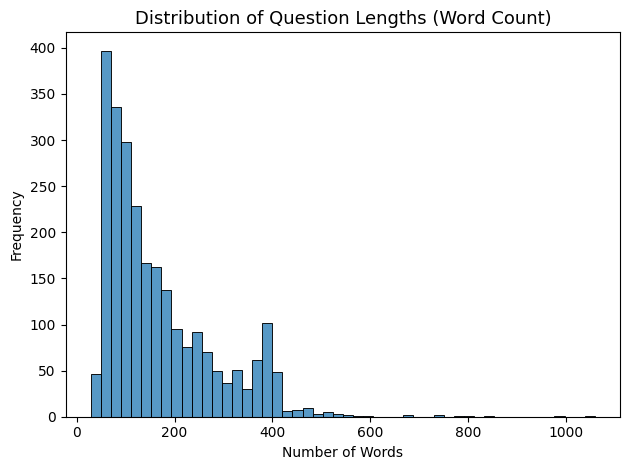

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.histplot(data=data, x='text_word_count')

plt.title('Distribution of Question Lengths (Word Count)', fontsize=13)
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [18]:
infos = {
  "mean": [167.3],
  "min": [29],
  "max" : [1059]
}

feature_infos = pd.DataFrame(infos)
feature_infos


,mean,min,max
0,167.3,29,1059


In [19]:
data["Patient Question"].nunique()

2529

# 🎯 Target (Distortion)

In [20]:
data.head()

,Id_Number,Patient Question,Distorted part,Dominant Distortion,Secondary Distortion (Optional),text_word_count
0,4500,"Hello, I have a beautiful,smart,outgoing and a...",The voice are always fimilar (someone she know...,Personalization,NaN,131
1,4501,Since I was about 16 years old I’ve had these ...,I feel trapped inside my disgusting self and l...,Labeling,Emotional Reasoning,292
2,4502,So I’ve been dating on and off this guy for a...,NaN,No Distortion,NaN,447
3,4503,My parents got divorced in 2004. My mother has...,NaN,No Distortion,NaN,181
4,4504,I don’t really know how to explain the situati...,I refused to go because I didn’t know if it wa...,Fortune-telling,Emotional Reasoning,295


In [21]:
data["Dominant Distortion"].value_counts()

Dominant Distortion
No Distortion              933
Mind Reading               239
Overgeneralization         239
Magnification              195
Labeling                   165
Personalization            153
Fortune-telling            143
Emotional Reasoning        134
Mental filter              122
Should statements          107
All-or-nothing thinking    100
Name: count, dtype: int64

In [22]:
data["Dominant Distortion"].nunique()

11

In [23]:
data["Dominant Distortion"].value_counts(normalize=True)

Dominant Distortion
No Distortion              0.368775
Mind Reading               0.094466
Overgeneralization         0.094466
Magnification              0.077075
Labeling                   0.065217
Personalization            0.060474
Fortune-telling            0.056522
Emotional Reasoning        0.052964
Mental filter              0.048221
Should statements          0.042292
All-or-nothing thinking    0.039526
Name: proportion, dtype: float64

count    1597.000000
mean        0.255636
std         0.212910
min         0.010929
25%         0.101562
50%         0.186813
75%         0.344262
max         1.103448
Name: distortion_pct, dtype: float64


<Axes: >

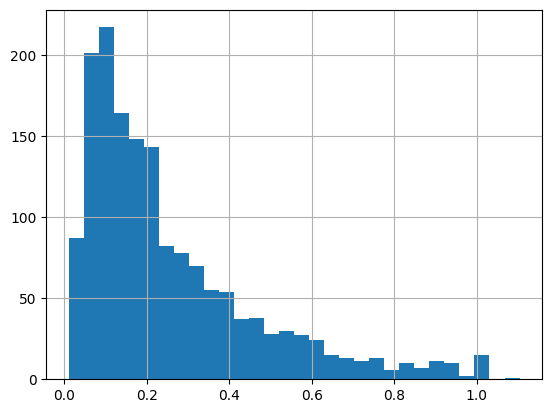

In [ ]:
# new data frame w only the distorted part, and the percentage of response and distorted part
df_distorted = data.dropna(subset=['Distorted part']).copy()

# Word-level percentage
df_distorted['dist_word_count'] = df_distorted['Distorted part'].apply(lambda x: len(str(x).split()))

df_distorted['distortion_pct'] = (df_distorted['dist_word_count'] / df_distorted['text_word_count'])

print(df_distorted['distortion_pct'].describe())

df_distorted['distortion_pct'].hist(bins=30)

In [27]:
data

,Id_Number,Patient Question,Distorted part,Dominant Distortion,Secondary Distortion (Optional),text_word_count
0,4500,"Hello, I have a beautiful,smart,outgoing and a...",The voice are always fimilar (someone she know...,Personalization,NaN,131
1,4501,Since I was about 16 years old I’ve had these ...,I feel trapped inside my disgusting self and l...,Labeling,Emotional Reasoning,292
2,4502,So I’ve been dating on and off this guy for a...,NaN,No Distortion,NaN,447
3,4503,My parents got divorced in 2004. My mother has...,NaN,No Distortion,NaN,181
4,4504,I don’t really know how to explain the situati...,I refused to go because I didn’t know if it wa...,Fortune-telling,Emotional Reasoning,295
...,...,...,...,...,...,...
2525,2562,I’m a 21 year old female. I spent most of my l...,NaN,No Distortion,NaN,72
2526,2563,I am 21 female and have not had any friends fo...,Now I am at university my peers around me all ...,Overgeneralization,NaN,191
2527,2564,From the U.S.: My brother is 19 years old and ...,He claims he’s severely depressed and has outb...,Mental filter,Mind Reading,80
2528,2565,From the U.S.: I am a 21 year old woman who ha...,NaN,No Distortion,NaN,69


In [28]:
df_distorted

,Id_Number,Patient Question,Distorted part,Dominant Distortion,Secondary Distortion (Optional),text_word_count,dist_word_count,distortion_pct
0,4500,"Hello, I have a beautiful,smart,outgoing and a...",The voice are always fimilar (someone she know...,Personalization,NaN,131,27,0.206107
1,4501,Since I was about 16 years old I’ve had these ...,I feel trapped inside my disgusting self and l...,Labeling,Emotional Reasoning,292,59,0.202055
4,4504,I don’t really know how to explain the situati...,I refused to go because I didn’t know if it wa...,Fortune-telling,Emotional Reasoning,295,54,0.183051
9,4510,I have been with my fiancé for two years now....,I felt like the response was totally irrationa...,Magnification,NaN,329,15,0.045593
10,4511,My husband and I have been married for over a ...,"I thought that he displayed traits of honor, l...",Labeling,NaN,63,26,0.412698
...,...,...,...,...,...,...,...,...
2519,2553,I feel overprotective about my mother because ...,"Since then, whenever my mother is out alone, I...",All-or-nothing thinking,Overgeneralization,236,118,0.500000
2522,2557,From Lebanon: I am dealing with a big problem!...,My family hate him but they didn’t met him at ...,Magnification,NaN,166,53,0.319277
2523,2559,"From the U.S.: I am a junior in high school, a...","However, I am not happy, at the least only hal...",Labeling,All-or-nothing thinking,205,54,0.263415
2526,2563,I am 21 female and have not had any friends fo...,Now I am at university my peers around me all ...,Overgeneralization,NaN,191,37,0.193717


# Dirty Data

In [32]:
# data where Distorted part>1.0
anomalies = df_distorted[df_distorted['distortion_pct'] > 1.0]
print(f"There are -{len(anomalies)}- feature where the distorted part is longer than the response. ")

for idx, row in anomalies.iterrows():
    print("---" * 10)
    print("Response:", row['Patient Question'])
    print("Distorted:", row['Distorted part'])

There are -1- feature where the distorted part is longer than the response. 
------------------------------
Response: Im 17 years old. ive lied about having an eating disorder and have been hospitalized many times. ive lied about trauma and have been hospitalized for it as well.
Distorted: i live a normal life otherwise but i just lie so much i don’t know what’s wrong with me or why i do it and im too far in to stop now.


In [38]:
# A function to check if distorted is really from the response(patient question)
def is_substring(row):
    resp = str(row['Patient Question']).lower().strip()
    dist = str(row['Distorted part']).lower().strip()
    return dist in resp

# Checking w the function (in df_distorted)
df_distorted['is_exact_match'] = df_distorted.apply(is_substring, axis=1)

# Results
print(df_distorted['is_exact_match'].value_counts())

is_exact_match
True     1355
False     242
Name: count, dtype: int64


In [46]:
# The percentage of the same word from the patient question
def word_overlap_ratio(row):
    resp_words = set(str(row['Patient Question']).lower().split())
    dist_words = set(str(row['Distorted part']).lower().split())
    if len(dist_words) == 0:
        return 0
    return len(dist_words.intersection(resp_words)) / len(dist_words)

df_distorted['word_overlap'] = df_distorted.apply(word_overlap_ratio, axis=1)

# Dirty data 0.5>
mismatched = df_distorted[df_distorted['word_overlap'] < 0.5]
print(f"There are -{len(mismatched)}- dirty data(s) (haven't check the order yet)")


for idx, row in mismatched.iterrows():
    print("---" * 10)
    print(f"Overlap_percentage: {row['word_overlap']:.2f}")
    print("Response:", row['Patient Question'])
    print("Distorted:", row['Distorted part'])

There are -3- dirty data(s) (haven't check the order yet)
------------------------------
Overlap_percentage: 0.16
Response: From a grandmother in Canada: My grandchildren ages 7 and 8 have been telling me for almost 2 years that they are afraid of mommy, my Grandson age 7 started soiling his pants, so I took him to the doctors and he said he’s afraid of mommy and she smacks them quite a bit in the head, I got the CPS involved and they sent the children to counselling. The counsellor seen the children one time and informed the children’s father the children are lying and are making stories up to get mommy and daddy back together.
Distorted:  People say overthinking is to think about a given issue way too much for me let’s say I had some trouble a week ago and now I have made a decision and that problem Is all solved and I know it however when I am free or happy I force myself to think about it and everything I just can’t stop it and I do that until I stop feeling happy.
----------------

In [37]:
df_distorted.head()

,Id_Number,Patient Question,Distorted part,Dominant Distortion,Secondary Distortion (Optional),text_word_count,dist_word_count,distortion_pct,is_exact_match,word_overlap
0,4500,"Hello, I have a beautiful,smart,outgoing and a...",The voice are always fimilar (someone she know...,Personalization,NaN,131,27,0.206107,True,1.000000
1,4501,Since I was about 16 years old I’ve had these ...,I feel trapped inside my disgusting self and l...,Labeling,Emotional Reasoning,292,59,0.202055,False,0.976190
4,4504,I don’t really know how to explain the situati...,I refused to go because I didn’t know if it wa...,Fortune-telling,Emotional Reasoning,295,54,0.183051,False,0.953488
9,4510,I have been with my fiancé for two years now....,I felt like the response was totally irrationa...,Magnification,NaN,329,15,0.045593,True,1.000000
10,4511,My husband and I have been married for over a ...,"I thought that he displayed traits of honor, l...",Labeling,NaN,63,26,0.412698,True,1.000000


In [56]:
# Double check if the words that are overlapping is in the same order

from difflib import SequenceMatcher


def ordered_match_ratio(row):
    resp = str(row['Patient Question']).lower().strip()
    dist = str(row['Distorted part']).lower().strip()
    if len(dist) == 0:
        return 0

    # SequenceMatcher 會依照順序尋找連續匹配的區塊
    matcher = SequenceMatcher(None, resp, dist)
    # 找出所有「按順序連續對上」的字元總長度
    matched_chars = sum(block.size for block in matcher.get_matching_blocks())

    # 計算 Distorted part 中，有多少比例是「按順序連續」出現在 Response 裡的
    return matched_chars / len(dist)

df_distorted['ordered_match'] = df_distorted.apply(ordered_match_ratio, axis=1)

# 找出「按順序連續匹配度」低於 80% 的資料
suspicious = df_distorted[df_distorted['ordered_match'] < 0.8]
print(f"There are {len(suspicious)} real dirty datas, which is around {round(len(df_distorted)/len(suspicious))} percent.")

There are 315 real dirty datas, which is around 5 percent.
